<a href="https://colab.research.google.com/github/anittajoshy2001-dot/Research_methods_tutorials/blob/main/7PAM2015_ReseachMethods_tutorial_2_imputation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tutorial 2: Applying imputation methods to a dataset

This tutorial allows you to test the imputation methods discussed in the lecture.

* Step 1: Load the **breast cancer** dataset, train a Random Forest classifier on it, and predict the whether a patient's tumor is benign or malignant.

* Step 2: Artificially introduce missing values to test out various methods

* Step 3: Apply imputation methods, visualise the distribution of variables and how well the imputation methods reproduce the original dataset.

* Step 4: Re-train the model for each method to verify how well it did compared to the full dataset for each imputation method you try

### Step 1:
Load, train, and predict on the original dataset without missing values

In [16]:
# Load required packages
import numpy as np
import pandas as pd
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, mean_squared_error
from matplotlib import pyplot as plt
import seaborn as sns

In [17]:
# Load breast cancer dataset
data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target, name="target")

X.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 30 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         5

In [18]:
def train_and_predict(X, y, random_state=42):
    #Split into train/test sets
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.3, random_state=random_state
    )

    # Define the model
    model = RandomForestClassifier(random_state=random_state)

    # Train the model on original data
    model.fit(X_train, y_train)

    # Make predictions
    predictions = model.predict(X_test)

    accuracy = accuracy_score(y_test, predictions)
    # Calculate performance measures
    print(classification_report(y_test, predictions))

    return X_train, X_test, y_train, y_test, predictions, accuracy

In [19]:
results = train_and_predict(X,y)

              precision    recall  f1-score   support

           0       0.98      0.94      0.96        63
           1       0.96      0.99      0.98       108

    accuracy                           0.97       171
   macro avg       0.97      0.96      0.97       171
weighted avg       0.97      0.97      0.97       171



### Step 2:
Introduce random missing values to 10% of the data

In [20]:
# Load a random number generator
rng = np.random.default_rng(seed=42)
# Create a mask by selecting random numbers below some threshold
missing_mask = rng.random(X.shape) < 0.10  # 10% missing
X_missing = X.mask(missing_mask)
X_missing.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,NaN,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,NaN,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,NaN,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,NaN,0.05999,...,23.57,25.53,152.50,1709.0,NaN,NaN,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,NaN,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,NaN,1297.0,NaN,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,NaN


Plot a histogram of one of the variables to visualise its missing values

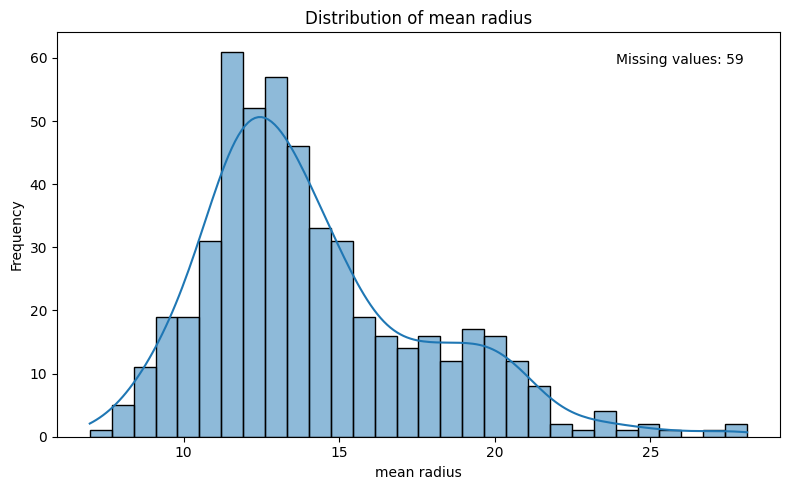

In [21]:
variable = "mean radius"

plt.figure(figsize=(8, 5))

sns.histplot(
    X_missing[variable].dropna(),
    bins=30,
    kde=True
)

missing_count = X_missing[variable].isnull().sum()

plt.title(f"Distribution of {variable}")
plt.xlabel(variable)
plt.ylabel("Frequency")

plt.text(
    0.95, 0.95,
    f"Missing values: {missing_count}",
    transform=plt.gca().transAxes,
    ha="right",
    va="top"
)

plt.tight_layout()
plt.show()

Make a heat map of all the missing values using the missingno package
(see https://github.com/ResidentMario/missingno for more information)

<Figure size 1400x800 with 0 Axes>

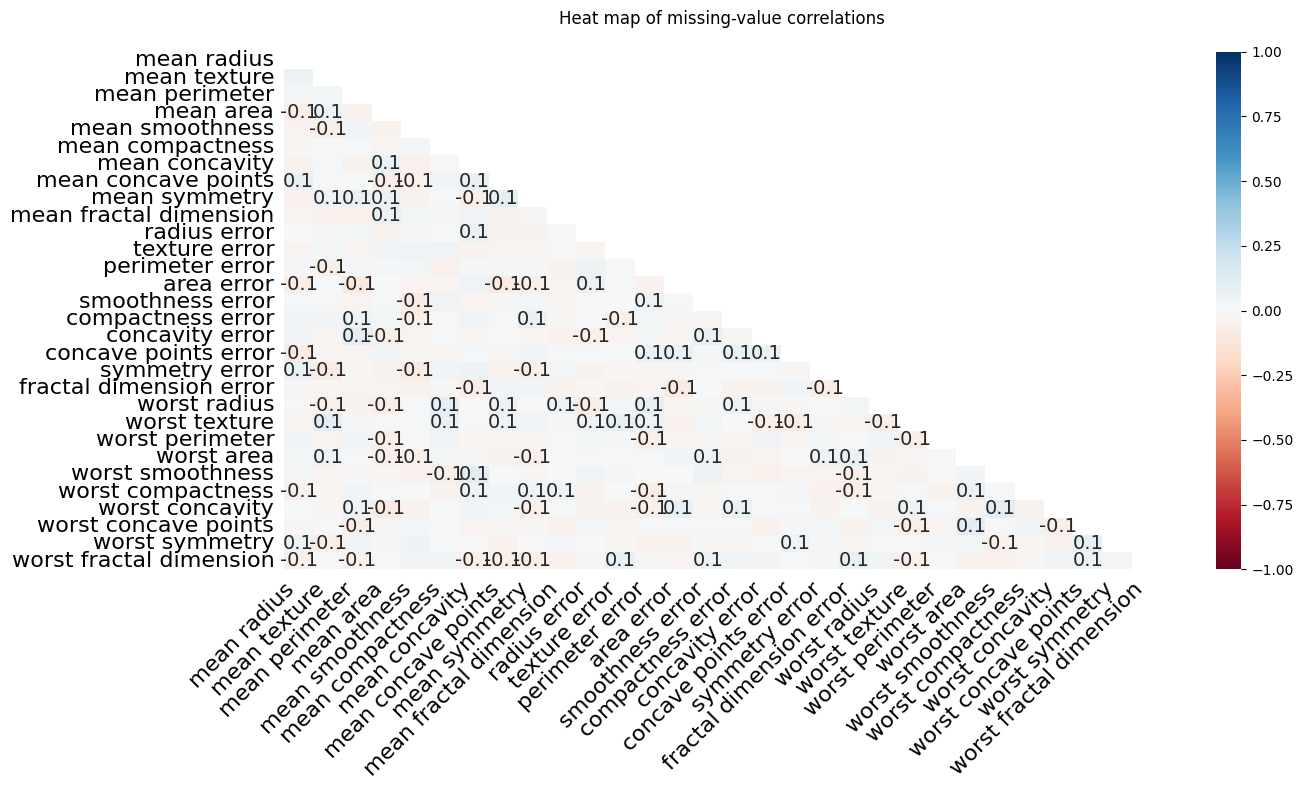

In [22]:
# Install missingno if it is not already available
%pip install missingno

import missingno as msno
import matplotlib.pyplot as plt

# Visualise missing-value patterns across all variables
fig = plt.figure(figsize=(14, 8))
msno.heatmap(X_missing, figsize=(14, 8))
plt.title("Heat map of missing-value correlations", pad=20)
plt.tight_layout()
plt.show()


Drop all NaNs and re-train model on the data without any missing values

In [23]:
# Drop rows containing any missing values
complete_rows = X_missing.dropna(axis=0, how="any").index

X_complete = X_missing.loc[complete_rows]
y_complete = y.loc[complete_rows]

# Check the remaining data
print("Rows before:", len(X_missing))
print("Rows after:", len(X_complete))
print("Missing values remaining:", X_complete.isna().sum().sum())

# Retrain and evaluate the model
results_complete = train_and_predict(X_complete, y_complete)

Rows before: 569
Rows after: 32
Missing values remaining: 0
              precision    recall  f1-score   support

           0       1.00      0.67      0.80         3
           1       0.88      1.00      0.93         7

    accuracy                           0.90        10
   macro avg       0.94      0.83      0.87        10
weighted avg       0.91      0.90      0.89        10



### Step 3:
Use methods learned from the lectures to impute missing values. Choose a few of the methods described in class and try out at least one univariate method and one multi-variate method.

In [24]:
############## ADD CODE HERE ##############
# Add code to apply imputation methods to the data - see Lecture 2 slides

from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.linear_model import BayesianRidge
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

# Split data into training and testing sets
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_missing, y, test_size=0.3, random_state=42, stratify=y
)

# Define the imputation methods
imputers = {
    "Mean imputation (univariate)": SimpleImputer(strategy="mean"),
    "Global kNN (multivariate)": KNNImputer(n_neighbors=5),
    "MICE (multivariate)": IterativeImputer(
        estimator=BayesianRidge(),
        max_iter=10,
        random_state=42
    )
}

# Apply each method and evaluate the classifier
imputation_results = {}

for name, imputer in imputers.items():
    X_train_imp = pd.DataFrame(
        imputer.fit_transform(X_train_raw),
        columns=X_train_raw.columns,
        index=X_train_raw.index
    )

    X_test_imp = pd.DataFrame(
        imputer.transform(X_test_raw),
        columns=X_test_raw.columns,
        index=X_test_raw.index
    )

    model = RandomForestClassifier(random_state=42)
    model.fit(X_train_imp, y_train)

    predictions = model.predict(X_test_imp)
    accuracy = accuracy_score(y_test, predictions)

    imputation_results[name] = accuracy

    print(f"\n{name}: Accuracy = {accuracy:.4f}")
    print(classification_report(y_test, predictions))

print("\nAccuracy comparison:")
for method, accuracy in imputation_results.items():
    print(f"{method}: {accuracy:.4f}")


Mean imputation (univariate): Accuracy = 0.9415
              precision    recall  f1-score   support

           0       0.92      0.92      0.92        64
           1       0.95      0.95      0.95       107

    accuracy                           0.94       171
   macro avg       0.94      0.94      0.94       171
weighted avg       0.94      0.94      0.94       171


Global kNN (multivariate): Accuracy = 0.9298
              precision    recall  f1-score   support

           0       0.91      0.91      0.91        64
           1       0.94      0.94      0.94       107

    accuracy                           0.93       171
   macro avg       0.93      0.93      0.93       171
weighted avg       0.93      0.93      0.93       171


MICE (multivariate): Accuracy = 0.9357
              precision    recall  f1-score   support

           0       0.92      0.91      0.91        64
           1       0.94      0.95      0.95       107

    accuracy                           0.94    

/usr/local/lib/python3.13/dist-packages/sklearn/impute/_iterative.py:895: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(


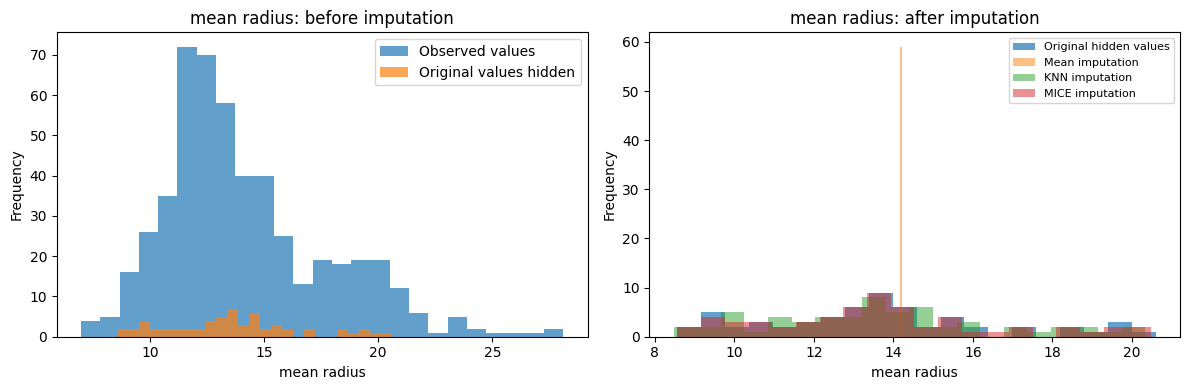

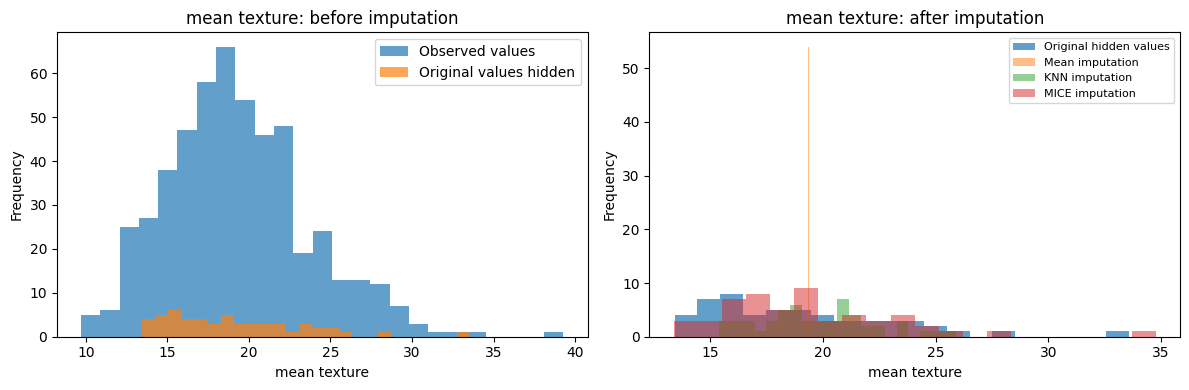

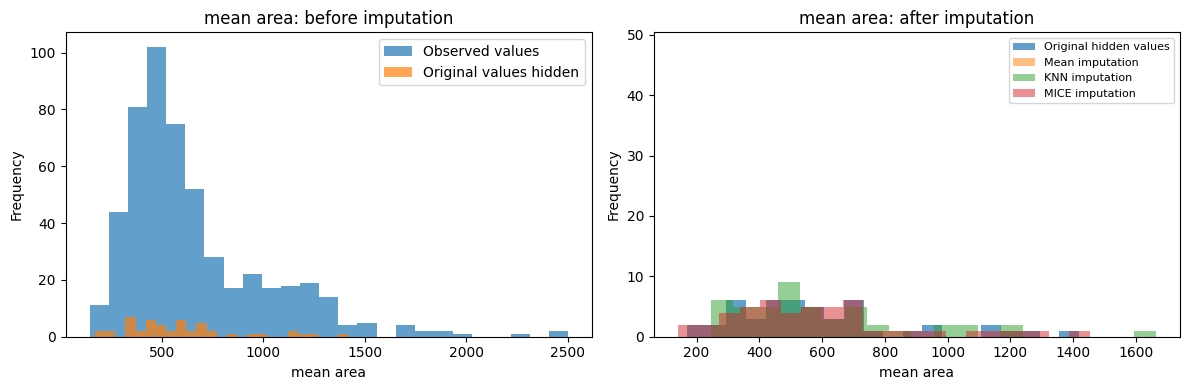

,Method,Feature,RMSE,RMSE / mean
0,Mean imputation,mean radius,2.962529,0.209703
1,Mean imputation,mean texture,4.146483,0.214959
2,Mean imputation,mean perimeter,21.211508,0.230638
3,Mean imputation,mean area,289.651589,0.442291
4,Mean imputation,mean smoothness,0.013560,0.140717
...,...,...,...,...
85,MICE imputation,worst compactness,0.031700,0.124672
86,MICE imputation,worst concavity,0.034312,0.126061
87,MICE imputation,worst concave points,0.011238,0.098061
88,MICE imputation,worst symmetry,0.024045,0.082893


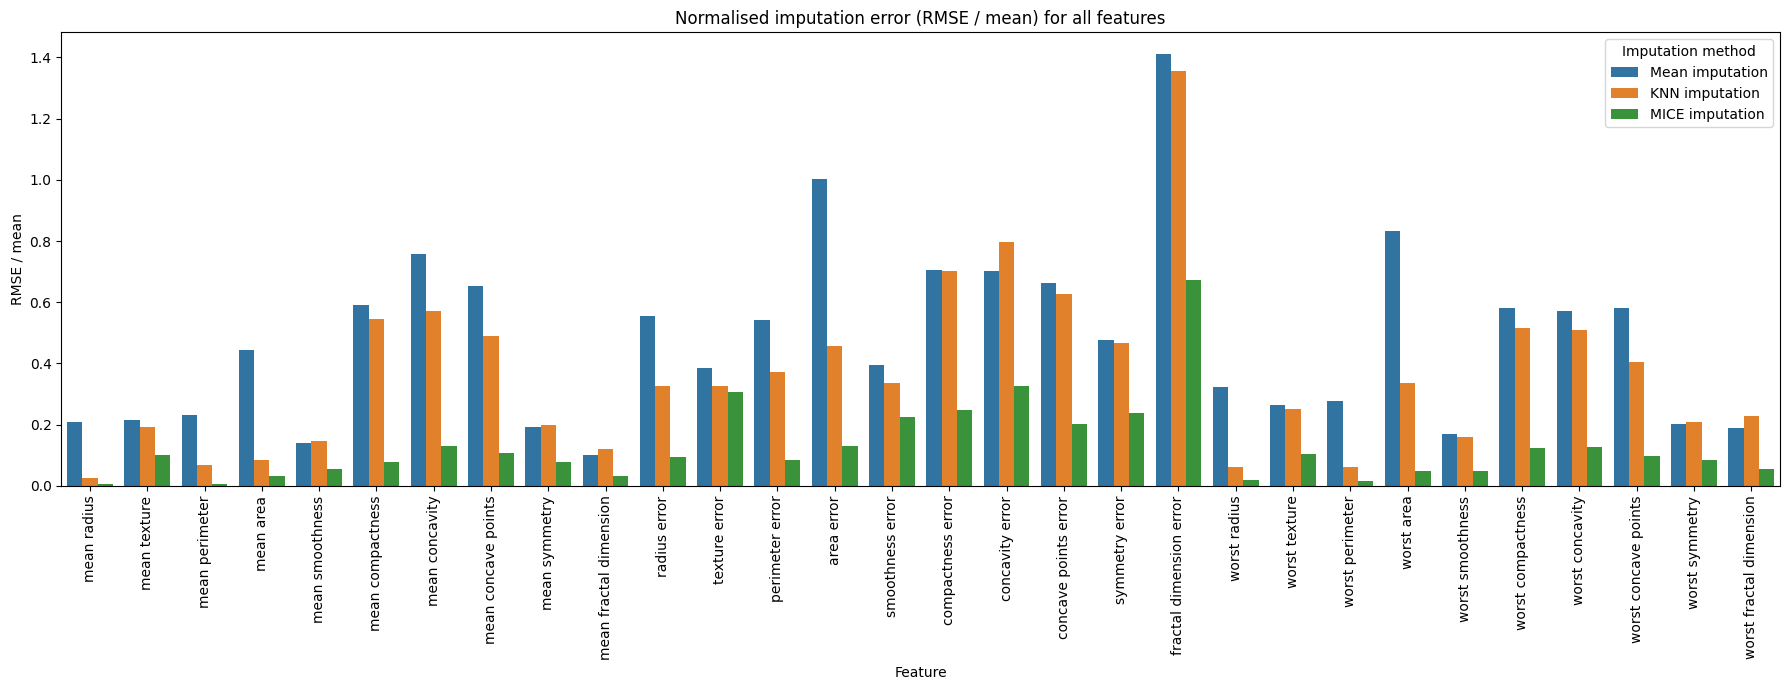

,Method,Average RMSE / mean
0,KNN imputation,0.364642
1,MICE imputation,0.129179
2,Mean imputation,0.478734


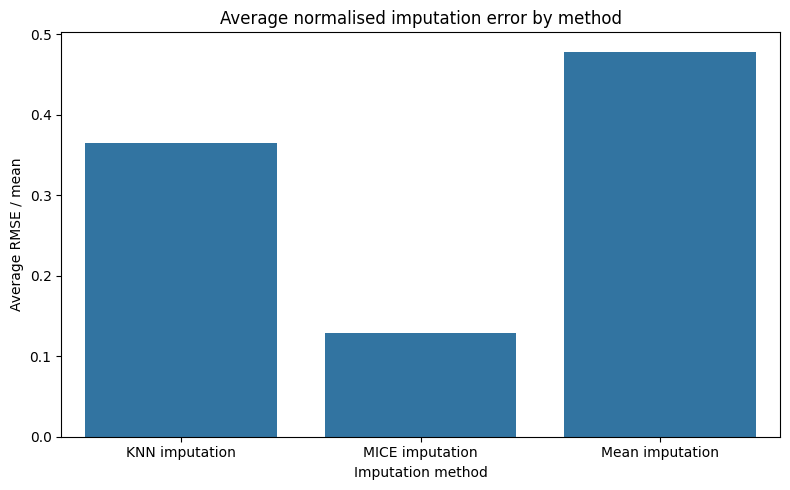

In [25]:
############## ADD CODE HERE ##############
# Plot single variables with dataset before and after imputation (like the plots shown in the lecture)
# Compute also the RMSE/ mean (i.e. divide RMSE by the mean) for each feature in the dataset by comparing the original columns with the imputed columns.
# ATTENTION: calculate this only for the values that are missing (not the full column). Use the code in the next cell for that.
# Make a plot with this comparison, both for all features and for the average RMSE/mean.


# ==========================================
# Step 4: Plot imputation results and calculate RMSE / mean
# ==========================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.experimental import enable_iterative_imputer  # noqa: F401
from sklearn.impute import IterativeImputer
from sklearn.linear_model import BayesianRidge
from sklearn.metrics import mean_squared_error

# Identify the values that were artificially made missing
# True only where X had an original value but X_missing now has NaN
missing_mask = X_missing.isna() & X.notna()

# Define the imputation methods
imputers = {
    "Mean imputation": SimpleImputer(strategy="mean"),
    "KNN imputation": KNNImputer(n_neighbors=5),
    "MICE imputation": IterativeImputer(
        estimator=BayesianRidge(),
        max_iter=10,
        random_state=42
    )
}

# Apply each method to the dataset with missing values
imputed_datasets = {}

for method, imputer in imputers.items():
    imputed_array = imputer.fit_transform(X_missing)
    imputed_df = pd.DataFrame(
        imputed_array,
        columns=X.columns,
        index=X.index
    )
    imputed_datasets[method] = imputed_df

# ------------------------------------------
# 1. Plot example features before and after imputation
# ------------------------------------------

example_features = ["mean radius", "mean texture", "mean area"]

for feature in example_features:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    # Original values and the values that were hidden
    observed = X_missing[feature].dropna()
    artificially_missing = missing_mask[feature]

    axes[0].hist(
        observed, bins=25, alpha=0.7,
        label="Observed values"
    )
    axes[0].hist(
        X.loc[artificially_missing, feature], bins=25, alpha=0.7,
        label="Original values hidden"
    )
    axes[0].set_title(f"{feature}: before imputation")
    axes[0].set_xlabel(feature)
    axes[0].set_ylabel("Frequency")
    axes[0].legend()

    # Compare original hidden values with imputed values
    axes[1].hist(
        X.loc[artificially_missing, feature],
        bins=20, alpha=0.7, label="Original hidden values"
    )

    for method, imputed_df in imputed_datasets.items():
        axes[1].hist(
            imputed_df.loc[artificially_missing, feature],
            bins=20, alpha=0.5, label=method
        )

    axes[1].set_title(f"{feature}: after imputation")
    axes[1].set_xlabel(feature)
    axes[1].set_ylabel("Frequency")
    axes[1].legend(fontsize=8)

    plt.tight_layout()
    plt.show()


# ------------------------------------------
# 2. Calculate RMSE / mean for every feature
#    using ONLY artificially missing values
# ------------------------------------------

results = []

for method, imputed_df in imputed_datasets.items():
    for feature in X.columns:

        # Evaluate only values that were artificially hidden
        mask = missing_mask[feature]

        actual = X.loc[mask, feature]
        predicted = imputed_df.loc[mask, feature]

        # Some features may have no artificially missing values
        if len(actual) == 0:
            rmse = np.nan
            rmse_over_mean = np.nan
        else:
            rmse = np.sqrt(mean_squared_error(actual, predicted))

            # Use absolute mean to keep the ratio non-negative
            feature_mean = abs(X[feature].mean())

            rmse_over_mean = (
                rmse / feature_mean
                if feature_mean != 0 else np.nan
            )

        results.append({
            "Method": method,
            "Feature": feature,
            "RMSE": rmse,
            "RMSE / mean": rmse_over_mean
        })

metrics_df = pd.DataFrame(results)

display(metrics_df)


# ------------------------------------------
# 3. Plot RMSE / mean for all features
# ------------------------------------------

plt.figure(figsize=(18, 7))

sns.barplot(
    data=metrics_df,
    x="Feature",
    y="RMSE / mean",
    hue="Method",
    errorbar=None
)

plt.title("Normalised imputation error (RMSE / mean) for all features")
plt.xlabel("Feature")
plt.ylabel("RMSE / mean")
plt.xticks(rotation=90)
plt.legend(title="Imputation method")
plt.tight_layout()
plt.show()


# ------------------------------------------
# 4. Plot average RMSE / mean by method
# ------------------------------------------

average_errors = (
    metrics_df.groupby("Method", as_index=False)["RMSE / mean"]
    .mean()
    .rename(columns={"RMSE / mean": "Average RMSE / mean"})
)

display(average_errors)

plt.figure(figsize=(8, 5))

sns.barplot(
    data=average_errors,
    x="Method",
    y="Average RMSE / mean",
    errorbar=None
)

plt.title("Average normalised imputation error by method")
plt.xlabel("Imputation method")
plt.ylabel("Average RMSE / mean")
plt.tight_layout()
plt.show()


In [26]:
def rmse_over_mean_imputation(original, imputed, mask):
    rmse_over_mean_per_feature = {}
    for col in original.columns:
        mask_col = mask[:, original.columns.get_loc(col)]
        if mask_col.any():  # compute only if some values were missing
            mse = mean_squared_error(
                original.loc[mask_col, col], imputed.loc[mask_col, col]
            )
            mean = original[col].mean()
            rmse_over_mean_per_feature[col] = np.sqrt(mse)/mean
    return pd.Series(rmse_over_mean_per_feature)

### Step 4:
Re-train your original model after imputation and compare results with each imputation method against the original results and those where rows with missing values were removed.

/usr/local/lib/python3.13/dist-packages/sklearn/impute/_iterative.py:895: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(


,Method,Accuracy,Accuracy (%)
0,Original data (no missing values),0.956140,95.614035
1,Drop rows with missing values,1.000000,100.000000
2,Mean imputation,0.947368,94.736842
3,KNN imputation,0.938596,93.859649
4,MICE imputation,0.947368,94.736842


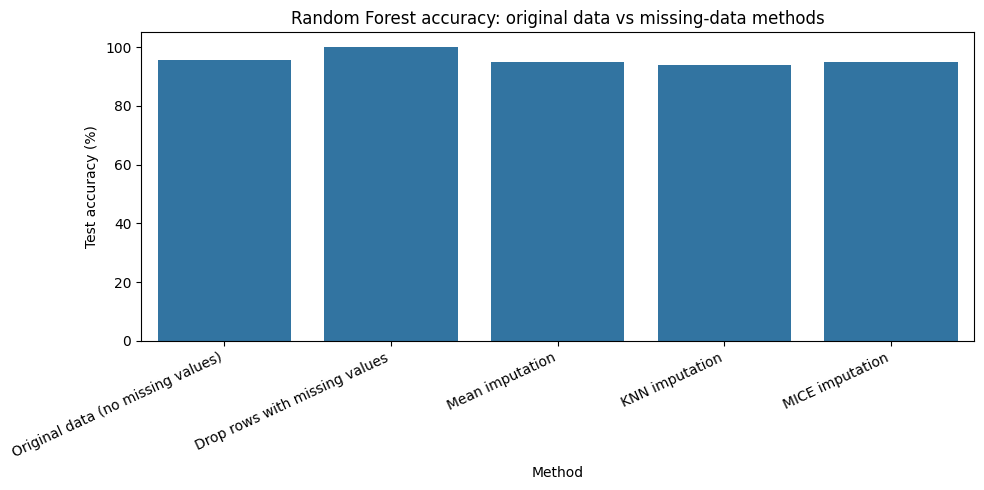

In [27]:
############## ADD CODE HERE ##############
# Copy & modify code from Step 1 to re-train, predict, and assess the effectiveness of imputing the data.


# Step 4: Retrain and compare model performance after imputation

from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.experimental import enable_iterative_imputer  # noqa: F401
from sklearn.impute import IterativeImputer
from sklearn.linear_model import BayesianRidge
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
import pandas as pd
import numpy as np

# Use the same split for every method to make the comparison fair
X_train_missing, X_test_missing, y_train, y_test = train_test_split(
    X_missing, y, test_size=0.2, random_state=42, stratify=y
)

# Original model performance (no artificially introduced missing values)
X_train_original, X_test_original, y_train_original, y_test_original = (
    train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
)

def evaluate_random_forest(X_train, X_test, y_train, y_test):
    """Train and evaluate the original Random Forest model."""
    model = RandomForestClassifier(random_state=42)
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    return accuracy_score(y_test, predictions)

results = []

# 1. Baseline: original complete dataset
original_accuracy = evaluate_random_forest(
    X_train_original, X_test_original, y_train_original, y_test_original
)
results.append({
    "Method": "Original data (no missing values)",
    "Accuracy": original_accuracy
})

# 2. Remove rows containing missing values
# Drop incomplete rows from train and test separately, preserving target alignment
train_complete_mask = X_train_missing.notna().all(axis=1)
test_complete_mask = X_test_missing.notna().all(axis=1)

X_train_complete = X_train_missing.loc[train_complete_mask]
y_train_complete = y_train.loc[train_complete_mask]

X_test_complete = X_test_missing.loc[test_complete_mask]
y_test_complete = y_test.loc[test_complete_mask]

if len(X_train_complete) > 0 and len(X_test_complete) > 0:
    drop_accuracy = evaluate_random_forest(
        X_train_complete, X_test_complete,
        y_train_complete, y_test_complete
    )
    results.append({
        "Method": "Drop rows with missing values",
        "Accuracy": drop_accuracy
    })
else:
    results.append({
        "Method": "Drop rows with missing values",
        "Accuracy": np.nan
    })

# 3. Imputation methods
imputers = {
    "Mean imputation": SimpleImputer(strategy="mean"),
    "KNN imputation": KNNImputer(n_neighbors=5),
    "MICE imputation": IterativeImputer(
        estimator=BayesianRidge(),
        max_iter=10,
        random_state=42
    )
}

for method_name, imputer in imputers.items():
    # Fit imputer on training data only to avoid data leakage
    X_train_imputed = pd.DataFrame(
        imputer.fit_transform(X_train_missing),
        columns=X.columns,
        index=X_train_missing.index
    )

    X_test_imputed = pd.DataFrame(
        imputer.transform(X_test_missing),
        columns=X.columns,
        index=X_test_missing.index
    )

    accuracy = evaluate_random_forest(
        X_train_imputed, X_test_imputed, y_train, y_test
    )

    results.append({
        "Method": method_name,
        "Accuracy": accuracy
    })

# Display and plot comparison
results_df = pd.DataFrame(results)
results_df["Accuracy (%)"] = results_df["Accuracy"] * 100

display(results_df)

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))
sns.barplot(data=results_df, x="Method", y="Accuracy (%)", errorbar=None)
plt.title("Random Forest accuracy: original data vs missing-data methods")
plt.ylabel("Test accuracy (%)")
plt.xlabel("Method")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()
